
# Evaluación Final - Ciencia de Datos Espaciales

**Estudiante:** Camila Alejandra Salazar Cisneros  
**Código:** 20190600  
**Departamentos asignados:** Lima, Ica y Huancavelica



## 1. Verificación de librerías

Se verifican las librerías necesarias para trabajar con datos geográficos y realizar el análisis espacial.


In [2]:

!pip show pysal pandas geopandas


Name: pysal
Version: 25.7
Summary: Meta Package for PySAL - A library of spatial analysis functions
Home-page: 
Author: 
Author-email: Serge Rey <sjsrey@gmail.com>, Levi Wolf <levi.john.wolf@gmail.com>
License: BSD 3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: access, beautifulsoup4, esda, geopandas, giddy, inequality, libpysal, mapclassify, mgwr, momepy, numpy, packaging, pandas, platformdirs, pointpats, requests, scikit-learn, scipy, segregation, shapely, spaghetti, spglm, spint, splot, spopt, spreg, tobler
Required-by: 
---
Name: pandas
Version: 2.2.3
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
All rights reserved.

Copyright (c) 2011-2023, Open source contributors.

Redistribution 

In [3]:

# Solo si es necesario instalar PySAL
# !pip install pysal



## 2. Carga y selección de datos

Se utiliza la base de datos `PeruMaps.gpkg`, seleccionando únicamente los distritos de los departamentos de Lima, Ica y Huancavelica.


In [6]:


import geopandas as gpd

# Descargar el mapa desde nuestro GitHub
url = "https://raw.githubusercontent.com/CamilaSalazar73/Evaluacion-Final-Ciencia-Datos-Espaciales/main/PeruMaps.gpkg"
!wget -q -O PeruMaps.gpkg {url}

# Cargar la capa de distritos
peru_distritos = gpd.read_file("PeruMaps.gpkg", layer="distritos")

# Seleccionar los departamentos asignados
departamentos = ["LIMA", "ICA", "HUANCAVELICA"]

peru_distritos = peru_distritos[
    peru_distritos["DEPARTAMEN"].str.strip().str.upper().isin(departamentos)
].copy()

# Revisar la información y el sistema de coordenadas
peru_distritos.info(), peru_distritos.crs.to_epsg(), peru_distritos.crs.is_projected



<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 314 entries, 220 to 1873
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   DEPARTAMEN                314 non-null    object  
 1   PROVINCIA                 314 non-null    object  
 2   DISTRITO                  314 non-null    object  
 3   Ubigeo                    314 non-null    object  
 4   Poblacion                 314 non-null    int64   
 5   Superficie                314 non-null    float64 
 6   IDH2019                   314 non-null    float64 
 7   Educ_sec_comp2019_pct     314 non-null    float64 
 8   NBI2017_pct               314 non-null    float64 
 9   Viv_sin_serv_hig2017_pct  314 non-null    float64 
 10  geometry                  314 non-null    geometry
dtypes: float64(5), geometry(1), int64(1), object(4)
memory usage: 29.4+ KB


(None, 4326, False)

In [7]:

peru_distritos.head()


,DEPARTAMEN,PROVINCIA,DISTRITO,Ubigeo,Poblacion,Superficie,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry
220,ICA,NAZCA,MARCONA,110304,12510,1955.20,0.677143,73.379122,17.0,4.7,"MULTIPOLYGON (((-74.71646 -14.9911, -74.71604 ..."
239,ICA,NAZCA,VISTA ALEGRE,110305,15935,527.30,0.592484,71.336705,30.0,4.9,"MULTIPOLYGON (((-74.93561 -14.84239, -74.9134 ..."
255,ICA,NAZCA,NAZCA,110301,27249,1252.25,0.598885,71.092375,21.6,7.1,"MULTIPOLYGON (((-74.83164 -14.69101, -74.83102..."
266,ICA,NAZCA,CHANGUILLO,110302,1457,946.94,0.535656,58.375209,37.2,14.4,"MULTIPOLYGON (((-75.36054 -14.59938, -75.35971..."
270,ICA,NAZCA,EL INGENIO,110303,2697,552.39,0.555823,65.161190,33.8,8.6,"MULTIPOLYGON (((-74.88994 -14.54718, -74.88937..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

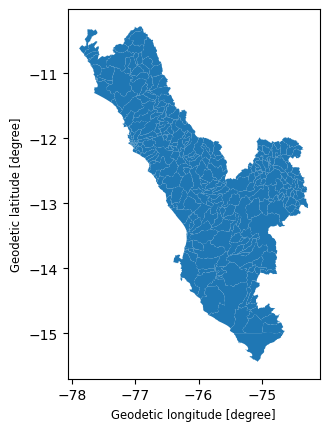

In [8]:

peru_distritos.plot()


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

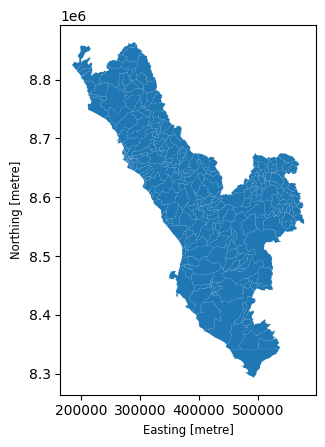

In [9]:

peru_distritos = peru_distritos.to_crs(32718)
peru_distritos.plot()


In [10]:

# Revisar si existen nombres de distritos repetidos
peru_distritos[peru_distritos["DISTRITO"].duplicated()]


,DEPARTAMEN,PROVINCIA,DISTRITO,Ubigeo,Poblacion,Superficie,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry
580,ICA,CHINCHA,PUEBLO NUEVO,110207,63297,209.45,0.592470,67.027851,23.5,1.0,"MULTIPOLYGON (((383897.99 8546574.45, 383939.2..."
671,HUANCAVELICA,CHURCAMPA,EL CARMEN,090504,3050,77.07,0.208963,35.214024,39.8,24.8,"MULTIPOLYGON (((553998.61 8603442.82, 554030.6..."
757,LIMA,HUAROCHIRI,CUENCA,150706,397,60.02,0.313482,51.373292,38.2,32.9,"MULTIPOLYGON (((340559 8661542, 340603 8661541..."
784,HUANCAVELICA,TAYACAJA,HUACHOCOLPA,090707,6534,292.00,0.296219,65.721200,55.9,44.2,"MULTIPOLYGON (((546687.72 8674823.11, 546767.5..."
856,LIMA,HUAROCHIRI,SAN ANTONIO,150716,5785,563.59,0.375590,39.073602,88.6,60.2,"MULTIPOLYGON (((322661.65 8711382.55, 322956.0..."
878,LIMA,HUAROCHIRI,LARAOS,150712,2452,104.51,0.457538,49.232739,54.3,40.1,"MULTIPOLYGON (((337726.66 8733024.25, 337753.4..."
1834,LIMA,LIMA,INDEPENDENCIA,150112,223827,14.56,0.685338,76.324286,18.7,1.2,"MULTIPOLYGON (((279197.469 8676433.089, 279219..."
1845,LIMA,LIMA,SAN LUIS,150134,59377,3.49,0.793258,80.699041,9.4,0.0,"MULTIPOLYGON (((282530.051 8665926.351, 282499..."
1855,LIMA,LIMA,SAN ISIDRO,150131,54298,11.10,0.788832,78.470219,1.1,0.0,"MULTIPOLYGON (((277019.308 8663207.821, 277130..."
1857,LIMA,LIMA,MIRAFLORES,150122,82898,9.62,0.832640,77.784099,1.2,0.0,"MULTIPOLYGON (((279465.859 8660533.526, 279503..."


In [11]:

# Comprobar si existen códigos Ubigeo repetidos
peru_distritos[peru_distritos["Ubigeo"].duplicated()]


,DEPARTAMEN,PROVINCIA,DISTRITO,Ubigeo,Poblacion,Superficie,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry


In [12]:

# Utilizar el Ubigeo como índice
peru_distritos.set_index("Ubigeo", inplace=True)

peru_distritos.head()


,DEPARTAMEN,PROVINCIA,DISTRITO,Poblacion,Superficie,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry
Ubigeo,,,,,,,,,,
110304,ICA,NAZCA,MARCONA,12510,1955.20,0.677143,73.379122,17.0,4.7,"MULTIPOLYGON (((530483.75 8342639.18, 530529.5..."
110305,ICA,NAZCA,VISTA ALEGRE,15935,527.30,0.592484,71.336705,30.0,4.9,"MULTIPOLYGON (((506927.52 8359105.55, 509316 8..."
110301,ICA,NAZCA,NAZCA,27249,1252.25,0.598885,71.092375,21.6,7.1,"MULTIPOLYGON (((518126 8375843, 518192 8375842..."
110302,ICA,NAZCA,CHANGUILLO,1457,946.94,0.535656,58.375209,37.2,14.4,"MULTIPOLYGON (((461168.08 8385952.32, 461257.6..."
110303,ICA,NAZCA,EL INGENIO,2697,552.39,0.555823,65.161190,33.8,8.6,"MULTIPOLYGON (((511857.16 8391754.58, 511917.6..."



## 3. Cálculo de vecindarios espaciales

Para analizar las relaciones de vecindad, primero se calcularán las distancias entre distritos. Se utilizará una muestra de los distritos de la provincia de Nazca, en Ica, para visualizar estas relaciones.


In [13]:

# Seleccionar los distritos de la provincia de Nazca
sub_distritos = peru_distritos[
    (peru_distritos["DEPARTAMEN"] == "ICA") &
    (peru_distritos["PROVINCIA"] == "NAZCA")
].copy()

# Calcular la matriz de distancias en kilómetros
sub_distritos.geometry.apply(
    lambda distrito: sub_distritos.distance(distrito) / 1000
)


Ubigeo,110304,110305,110301,110302,110303
Ubigeo,,,,,
110304,0.000000,0.000000,0.0,0.000000,21.443179
110305,0.000000,0.000000,0.0,24.812301,5.212591
110301,0.000000,0.000000,0.0,0.000000,0.000000
110302,0.000000,24.812301,0.0,0.000000,0.000000
110303,21.443179,5.212591,0.0,0.000000,0.000000


(8292633.000007629, 8392028.339997085)

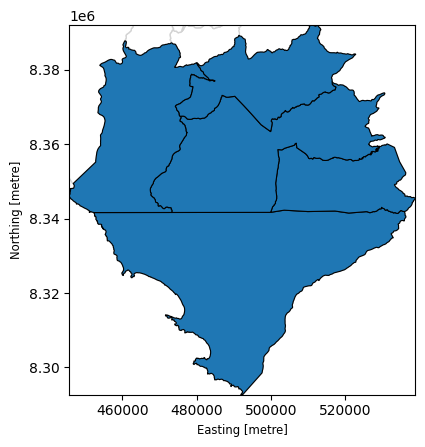

In [18]:

# Obtener los límites de la zona seleccionada
minx, miny, maxx, maxy = sub_distritos.total_bounds

# Mostrar los distritos seleccionados
base = peru_distritos.plot(facecolor="white", edgecolor="lightgrey")
sub_distritos.plot(ax=base, edgecolor="black", linewidth=0.8)

# Ajustar la visualización
base.set_xlim(minx, maxx)
base.set_ylim(miny, maxy)




### Tipos de vecindad espacial

Los vecinos espaciales pueden identificarse según dos criterios principales:

- **Contigüidad:** considera vecinos a los distritos que comparten límites, ya sea un borde (Rook) o un vértice o borde (Queen).
- **Proximidad:** identifica vecinos según su cercanía, utilizando distancias o un número determinado de vecinos más próximos.

Estas relaciones permiten construir las matrices de pesos espaciales que utilizaremos posteriormente para calcular los mapas LISA.


In [19]:

from libpysal.graph import Graph

# Para obtener resultados reproducibles
from numpy.random import seed
seed(42)



### 3.1. Vecindad por contigüidad binaria

La vecindad por contigüidad identifica qué distritos comparten límites geográficos. Se consideran dos criterios:

- **Rook:** dos distritos son vecinos cuando comparten un borde.
- **Queen:** dos distritos son vecinos cuando comparten un borde o un vértice.



#### 3.1.1. Vecindad Rook

Se identifican los distritos vecinos que comparten un borde, utilizando como ejemplo los cinco distritos de la provincia de Nazca.


In [20]:

# Construir las relaciones de vecindad Rook
rook = Graph.build_contiguity(sub_distritos, rook=True)


In [21]:

rook.adjacency


focal   neighbor
110304  110305      1
        110301      1
        110302      1
110305  110304      1
        110301      1
110301  110304      1
        110305      1
        110302      1
        110303      1
110302  110304      1
        110301      1
        110303      1
110303  110301      1
        110302      1
Name: weight, dtype: int64

In [22]:

import pandas as pd

pd.DataFrame(rook.adjacency).unstack()


weight                            
neighbor 110304 110305 110301 110302 110303
focal                                      
110304      NaN    1.0    1.0    1.0    NaN
110305      1.0    NaN    1.0    NaN    NaN
110301      1.0    1.0    NaN    1.0    1.0
110302      1.0    NaN    1.0    NaN    1.0
110303      NaN    NaN    1.0    1.0    NaN

In [23]:

# Reemplazar los valores faltantes por cero
rook_Matrix = pd.DataFrame(rook.adjacency).unstack().fillna(0)

rook_Matrix


weight                            
neighbor 110304 110305 110301 110302 110303
focal                                      
110304      0.0    1.0    1.0    1.0    0.0
110305      1.0    0.0    1.0    0.0    0.0
110301      1.0    1.0    0.0    1.0    1.0
110302      1.0    0.0    1.0    0.0    1.0
110303      0.0    0.0    1.0    1.0    0.0

In [24]:

# Función para construir matrices de adyacencia
toWideMatrix = lambda g: pd.DataFrame(g.adjacency).unstack().fillna(0)



#### Visualización de la vecindad Rook

Se representan las conexiones entre los distritos vecinos para observar las relaciones espaciales identificadas mediante el criterio Rook.


In [27]:



# Configurar el mapa interactivo de vecindad Rook
general_arguments = dict(
    gdf=sub_distritos,
    node_kws=dict(color="red"),
    edge_kws=dict(alpha=0.4, color="blue"),
    tiles="OpenStreetMap.HOT",
    zoom_start=8
)

rook.explore(**general_arguments)





#### 3.1.2. Vecindad Queen

A diferencia de Rook, el método Queen considera vecinos a los distritos que comparten un borde o al menos un vértice. Esto permite identificar un mayor número de relaciones de vecindad.


In [28]:

# Construir las relaciones de vecindad Queen
queen = Graph.build_contiguity(sub_distritos, rook=False)

# Obtener la matriz de adyacencia
queen_Matrix = toWideMatrix(queen)
queen_Matrix


weight                            
neighbor 110304 110305 110301 110302 110303
focal                                      
110304      0.0    1.0    1.0    1.0    0.0
110305      1.0    0.0    1.0    0.0    0.0
110301      1.0    1.0    0.0    1.0    1.0
110302      1.0    0.0    1.0    0.0    1.0
110303      0.0    0.0    1.0    1.0    0.0

In [29]:

# Visualizar las relaciones de vecindad Queen
queen.explore(**general_arguments)



### 3.2. Vecindad por proximidad

Este criterio identifica a los distritos vecinos según su cercanía, sin necesidad de que compartan límites geográficos.



#### 3.2.1. Vecinos más cercanos (KNN)

El método KNN identifica un número determinado de distritos vecinos según la distancia entre sus puntos representativos. En este caso, se consideran los tres vecinos más cercanos de cada distrito.


In [30]:

# Identificar los tres vecinos más cercanos
knn3 = Graph.build_knn(
    sub_distritos.representative_point(),
    k=3
)

# Obtener la matriz de adyacencia
knn3_Matrix = toWideMatrix(knn3)
knn3_Matrix


weight                            
neighbor 110304 110305 110301 110302 110303
focal                                      
110304      0.0    1.0    1.0    1.0    0.0
110305      1.0    0.0    1.0    0.0    1.0
110301      0.0    1.0    0.0    1.0    1.0
110302      1.0    0.0    1.0    0.0    1.0
110303      0.0    1.0    1.0    1.0    0.0

In [31]:

# Visualizar los tres vecinos más cercanos
knn3.explore(**general_arguments)



#### 3.2.2. Vecindad por distancia (Distance Band)

Este método considera vecinos a los distritos cuyos puntos representativos se encuentran dentro de una distancia determinada. Para el ejemplo de Nazca, se utilizará una distancia máxima de 100 km.


In [32]:

# Construir vecindarios dentro de una distancia de 100 km
band100k_Bi = Graph.build_distance_band(
    sub_distritos.representative_point(),
    threshold=100000
)

# Obtener la matriz de adyacencia
band100k_Bi_Matrix = toWideMatrix(band100k_Bi)
band100k_Bi_Matrix


weight                            
neighbor 110304 110305 110301 110302 110303
focal                                      
110304      0.0    1.0    1.0    1.0    1.0
110305      1.0    0.0    1.0    1.0    1.0
110301      1.0    1.0    0.0    1.0    1.0
110302      1.0    1.0    1.0    0.0    1.0
110303      1.0    1.0    1.0    1.0    0.0

In [33]:

# Visualizar las relaciones dentro de los 100 km
band100k_Bi.explore(**general_arguments)



### 3.3. Vecindad por proximidad continua

A diferencia de la vecindad binaria, este método asigna pesos a las relaciones espaciales según la distancia entre los distritos. De esta manera, los distritos más cercanos tienen mayor influencia que los más alejados.


In [34]:

# Construir la vecindad continua dentro de 100 km
band100k_C = Graph.build_distance_band(
    sub_distritos.representative_point(),
    threshold=100000,
    binary=False
)

# Obtener la matriz de pesos espaciales
band100k_C_Matrix = toWideMatrix(band100k_C)
band100k_C_Matrix


/usr/local/lib/python3.13/dist-packages/libpysal/graph/base.py:839: RuntimeWarning: divide by zero encountered in power
  kernel=lambda distances, alpha: np.power(distances, alpha),


weight                                        
neighbor    110304    110305    110301    110302    110303
focal                                                     
110304    0.000000  0.000023  0.000024  0.000019  0.000017
110305    0.000023  0.000000  0.000034  0.000018  0.000031
110301    0.000024  0.000034  0.000000  0.000041  0.000048
110302    0.000019  0.000018  0.000041  0.000000  0.000028
110303    0.000017  0.000031  0.000048  0.000028  0.000000

In [35]:

# Visualizar las relaciones de proximidad continua
band100k_C.explore(**general_arguments)


In [36]:

# Visualizar las relaciones de un distrito
focal_args = dict(
    gdf=sub_distritos,
    focal="110301",
    edge_kws=dict(
        column="weight",
        style_kws=dict(weight=6)
    ),
    zoom_start=9,
    tiles="OpenStreetMap.HOT"
)

band100k_C.explore(**focal_args)



### 3.4. Vecindad Kernel KNN

Este método identifica los tres distritos más cercanos, pero también asigna un peso a cada relación según la distancia. Los vecinos más próximos reciben una mayor ponderación.


In [37]:

# Construir el vecindario Kernel con tres vecinos
kernel3 = Graph.build_kernel(
    sub_distritos.representative_point(),
    k=3
)

# Obtener la matriz de pesos espaciales
kernel3_Matrix = toWideMatrix(kernel3)
kernel3_Matrix


weight                                        
neighbor    110304    110305    110301    110302    110303
focal                                                     
110304    0.000000  0.288111  0.294349  0.241971  0.000000
110305    0.288111  0.000000  0.341897  0.000000  0.329955
110301    0.000000  0.341897  0.000000  0.358061  0.369219
110302    0.241971  0.000000  0.358061  0.000000  0.316163
110303    0.000000  0.329955  0.369219  0.316163  0.000000

In [38]:

# Visualizar las relaciones Kernel KNN
kernel3.explore(**general_arguments)


In [39]:

# Visualizar los pesos Kernel KNN del distrito de Nazca
kernel3.explore(**focal_args)



### 3.5. Contigüidad ponderada por perímetro

Este método identifica a los distritos que comparten un borde y asigna un peso según la longitud del límite compartido. Cuanto mayor es esta longitud, mayor es el peso de la relación espacial.


In [40]:

# Construir la vecindad según la longitud del borde compartido
perimeter = Graph.build_contiguity(
    sub_distritos,
    by_perimeter=True
)

# Obtener la matriz de pesos espaciales
perimeter_Matrix = toWideMatrix(perimeter)
perimeter_Matrix


weight                                                        
neighbor        110304        110305        110301        110302        110303
focal                                                                         
110304        0.000000  37933.831132  26569.427022  20959.303341      0.000000
110305    37933.831132      0.000000  54070.605465      0.000000      0.000000
110301    26569.427022  54070.605465      0.000000  35347.153197  60541.296918
110302    20959.303341      0.000000  35347.153197      0.000000  29596.618068
110303        0.000000      0.000000  60541.296918  29596.618068      0.000000

In [41]:

# Visualizar las relaciones por perímetro compartido
perimeter.explore(**general_arguments)


In [42]:

# Visualizar los pesos por perímetro del distrito de Nazca
perimeter.explore(**focal_args)



### 3.6. Comparación de los métodos de vecindad

| Método | Criterio de vecindad | Tipo de peso |
|---|---|---|
| Rook | Comparten un borde | Binario |
| Queen | Comparten un borde o vértice | Binario |
| KNN | Tres vecinos más cercanos | Binario |
| Distance Band | Distancia máxima de 100 km | Binario |
| Distance Band continuo | Distancia máxima de 100 km | Continuo según distancia |
| Kernel KNN | Tres vecinos más cercanos | Continuo según distancia |
| Perímetro | Longitud del borde compartido | Continuo según longitud |



## 4. Pesos espaciales

Se revisan los pesos asignados a los vecinos según cada método y se normalizan para que su suma sea igual a 1. Esto permitirá comparar las relaciones espaciales y utilizarlas posteriormente en el análisis.


In [43]:

# Sumar los pesos de cada método de vecindad
allMx = [
    rook_Matrix.sum(axis=1),
    queen_Matrix.sum(axis=1),
    knn3_Matrix.sum(axis=1),
    band100k_Bi_Matrix.sum(axis=1),
    band100k_C_Matrix.sum(axis=1),
    kernel3_Matrix.sum(axis=1),
    perimeter_Matrix.sum(axis=1)
]

pd.concat(allMx, axis=1)


,0,1,2,3,4,5,6
focal,,,,,,,
110304,3.0,3.0,3.0,4.0,0.000083,0.824431,85462.561494
110305,2.0,2.0,3.0,4.0,0.000106,0.959963,92004.436596
110301,4.0,4.0,3.0,4.0,0.000146,1.069177,176528.482601
110302,3.0,3.0,3.0,4.0,0.000105,0.916195,85903.074606
110303,2.0,2.0,3.0,4.0,0.000123,1.015337,90137.914986


In [44]:

queen_Matrix


weight                            
neighbor 110304 110305 110301 110302 110303
focal                                      
110304      0.0    1.0    1.0    1.0    0.0
110305      1.0    0.0    1.0    0.0    0.0
110301      1.0    1.0    0.0    1.0    1.0
110302      1.0    0.0    1.0    0.0    1.0
110303      0.0    0.0    1.0    1.0    0.0

In [45]:

# Normalizar los pesos de la vecindad Queen
toWideMatrix(queen.transform("r"))


weight                                        
neighbor    110304    110305    110301    110302    110303
focal                                                     
110304    0.000000  0.333333  0.333333  0.333333  0.000000
110305    0.500000  0.000000  0.500000  0.000000  0.000000
110301    0.250000  0.250000  0.000000  0.250000  0.250000
110302    0.333333  0.000000  0.333333  0.000000  0.333333
110303    0.000000  0.000000  0.500000  0.500000  0.000000

In [46]:

perimeter_Matrix


weight                                                        
neighbor        110304        110305        110301        110302        110303
focal                                                                         
110304        0.000000  37933.831132  26569.427022  20959.303341      0.000000
110305    37933.831132      0.000000  54070.605465      0.000000      0.000000
110301    26569.427022  54070.605465      0.000000  35347.153197  60541.296918
110302    20959.303341      0.000000  35347.153197      0.000000  29596.618068
110303        0.000000      0.000000  60541.296918  29596.618068      0.000000

In [47]:

# Comprobar la suma de los pesos por distrito
pd.concat([
    perimeter_Matrix,
    perimeter_Matrix.sum(axis=1).rename("SUM")
], axis=1)


,"(weight, 110304)","(weight, 110305)","(weight, 110301)","(weight, 110302)","(weight, 110303)",SUM
focal,,,,,,
110304,0.000000,37933.831132,26569.427022,20959.303341,0.000000,85462.561494
110305,37933.831132,0.000000,54070.605465,0.000000,0.000000,92004.436596
110301,26569.427022,54070.605465,0.000000,35347.153197,60541.296918,176528.482601
110302,20959.303341,0.000000,35347.153197,0.000000,29596.618068,85903.074606
110303,0.000000,0.000000,60541.296918,29596.618068,0.000000,90137.914986


In [48]:

# Normalizar los pesos según el perímetro compartido
toWideMatrix(perimeter.transform("r"))


weight                                        
neighbor    110304    110305    110301    110302    110303
focal                                                     
110304    0.000000  0.443865  0.310890  0.245245  0.000000
110305    0.412304  0.000000  0.587696  0.000000  0.000000
110301    0.150511  0.306300  0.000000  0.200235  0.342955
110302    0.243988  0.000000  0.411477  0.000000  0.344535
110303    0.000000  0.000000  0.671652  0.328348  0.000000

In [49]:

# Verificar que los pesos normalizados sumen 1
Mtrans = toWideMatrix(perimeter.transform("r"))

pd.concat([
    Mtrans,
    Mtrans.sum(axis=1).rename("SUM")
], axis=1)


,"(weight, 110304)","(weight, 110305)","(weight, 110301)","(weight, 110302)","(weight, 110303)",SUM
focal,,,,,,
110304,0.000000,0.443865,0.310890,0.245245,0.000000,1.0
110305,0.412304,0.000000,0.587696,0.000000,0.000000,1.0
110301,0.150511,0.306300,0.000000,0.200235,0.342955,1.0
110302,0.243988,0.000000,0.411477,0.000000,0.344535,1.0
110303,0.000000,0.000000,0.671652,0.328348,0.000000,1.0



## 5. Análisis de la variable educativa

Se analiza el porcentaje de población que completó la educación secundaria en 2019 (`Educ_sec_comp2019_pct`) para los distritos de Lima, Ica y Huancavelica.

Primero se revisan sus estadísticas descriptivas y luego se representa su distribución geográfica mediante un mapa de cuantiles.


In [50]:

# Revisar las estadísticas de la variable educativa
peru_distritos.Educ_sec_comp2019_pct.describe()


,Educ_sec_comp2019_pct
count,314.000000
mean,62.362036
std,14.336951
min,12.358409
25%,52.599675
50%,64.259557
75%,73.866469
max,89.576693


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

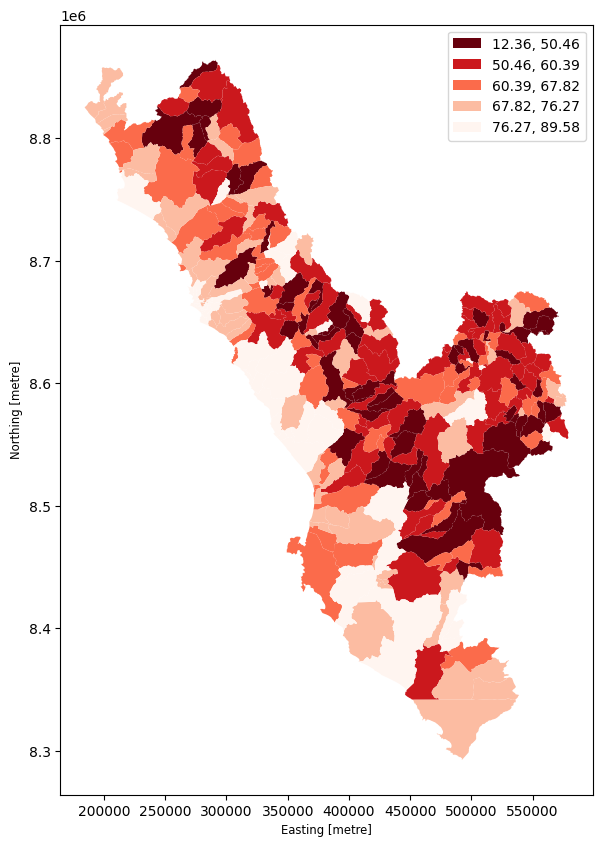

In [51]:

# Representar la distribución de la educación secundaria
peru_distritos.plot(
    "Educ_sec_comp2019_pct",
    scheme="quantiles",
    cmap="Reds_r",
    legend=True,
    figsize=(12, 10)
)



### 5.1. Preparación de las geometrías

Se utiliza la capa `good_geom`, que contiene geometrías corregidas, para calcular las relaciones de vecindad de los distritos seleccionados. Estas relaciones se ponderan según la longitud de los bordes compartidos.


In [52]:

# Cargar las geometrías corregidas
peru_good = gpd.read_file("PeruMaps.gpkg", layer="good_geom")

# Seleccionar Lima, Ica y Huancavelica
peru_good = peru_good[
    peru_good["DEPARTAMENTO"].str.strip().str.upper().isin(departamentos)
].copy()

# Proyectar el mapa y ordenar los índices
peru_good = peru_good.to_crs(32718).reset_index(drop=True)

# Verificar los distritos seleccionados
print("Total de distritos:", len(peru_good))
peru_good["DEPARTAMENTO"].value_counts()


Total de distritos: 314


,count
DEPARTAMENTO,
Lima,171
Huancavelica,100
Ica,43


In [53]:

# Construir la vecindad según el perímetro compartido
peru_perim = Graph.build_contiguity(
    peru_good,
    by_perimeter=True
)

# Revisar los distritos sin vecinos
peru_perim.isolates


Index([], dtype='int64', name='focal')

In [54]:

# Excluir los distritos sin vecinos
islandCodes = peru_perim.isolates

peru_clean = peru_good.drop(index=islandCodes).copy()
peru_clean = peru_clean.reset_index(drop=True)

# Reconstruir y normalizar la matriz de pesos
peru_perim_clean = Graph.build_contiguity(
    peru_clean,
    by_perimeter=True
).transform("r")

print("Distritos utilizados:", len(peru_clean))
print("Distritos excluidos:", len(peru_good) - len(peru_clean))


Distritos utilizados: 314
Distritos excluidos: 0



### 5.2. Rezago espacial de la educación secundaria

Se calcula el rezago espacial del porcentaje de población con educación secundaria completa, considerando los pesos de vecindad normalizados. Esto permite comparar los valores de cada distrito con los de sus vecinos.


In [56]:

# Calcular el rezago espacial de la variable educativa
ylag = peru_perim_clean.lag(
    peru_clean["Educ_sec_comp2019_pct"]
)


In [57]:

# Agregar el promedio ponderado de los vecinos
peru_clean = peru_clean.assign(
    Educ_sec_comp2019_pct_lagged=ylag
)

peru_clean.head()


,DEPARTAMENTO,PROVINCIA,DISTRITO,ubigeo,Poblacion,IDH2019,Educ_sec_comp2019_pct,NBI2017_pct,Viv_sin_serv_hig2017_pct,geometry,Educ_sec_comp2019_pct_lagged
0,Huancavelica,ACOBAMBA,ACOBAMBA,PE090201,10258,0.449410,62.337880,21.3,10.3,"MULTIPOLYGON (((550033.762 8590870.065, 550087...",53.738859
1,Huancavelica,HUANCAVELICA,ACOBAMBILLA,PE090102,4730,0.298679,60.738434,43.2,32.1,"MULTIPOLYGON (((477288.071 8609238.955, 477262...",54.678078
2,Huancavelica,HUANCAVELICA,ACORIA,PE090103,37509,0.266345,57.333580,40.2,27.4,"MULTIPOLYGON (((533456.922 8615719.597, 533500...",59.486719
3,Huancavelica,TAYACAJA,ACOSTAMBO,PE090702,4110,0.319751,47.732470,31.0,20.3,"MULTIPOLYGON (((500898.865 8636324.082, 500955...",56.337349
4,Huancavelica,TAYACAJA,ACRAQUIA,PE090703,5014,0.358396,50.769991,20.7,10.0,"MULTIPOLYGON (((506486.538 8635957.075, 506649...",55.410271


<Axes: xlabel='Educ_sec_comp2019_pct', ylabel='Educ_sec_comp2019_pct_lagged'>

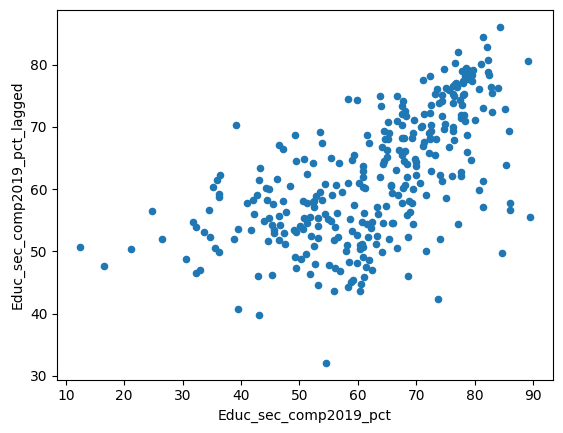

In [58]:

# Comparar el porcentaje educativo con el de los vecinos
peru_clean.plot.scatter(
    "Educ_sec_comp2019_pct",
    "Educ_sec_comp2019_pct_lagged"
)



## 6. Autocorrelación espacial

Se analiza si los porcentajes de educación secundaria de los distritos presentan patrones de agrupación espacial o si se distribuyen de manera aleatoria.



### 6.1. Índice de Moran Global

Se calcula el índice de Moran Global para evaluar si existe autocorrelación espacial en los porcentajes de educación secundaria de los distritos seleccionados.


In [59]:

import esda

# Calcular el índice de Moran Global
MoranGlobal_HS = esda.Moran(
    peru_clean["Educ_sec_comp2019_pct"],
    peru_perim_clean
)


In [ ]:

# Revisar el índice de Moran y su significancia
MoranGlobal_HS.I, MoranGlobal_HS.p_sim



### 6.2. Índice de Moran Local (LISA)

Se utiliza el índice de Moran Local para identificar agrupaciones espaciales y valores atípicos en los porcentajes de educación secundaria. Los resultados permitirán distinguir cuatro patrones:

- **HotSpot (Alto-Alto):** distritos con valores altos rodeados de valores altos.
- **ColdSpot (Bajo-Bajo):** distritos con valores bajos rodeados de valores bajos.
- **HotOutlier (Alto-Bajo):** distritos con valores altos rodeados de valores bajos.
- **ColdOutlier (Bajo-Alto):** distritos con valores bajos rodeados de valores altos.

Se considera un nivel de significancia del 5 %.


In [60]:

# Calcular el índice de Moran Local
lisa = esda.Moran_Local(
    peru_clean["Educ_sec_comp2019_pct"],
    peru_perim_clean,
    seed=42
)


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

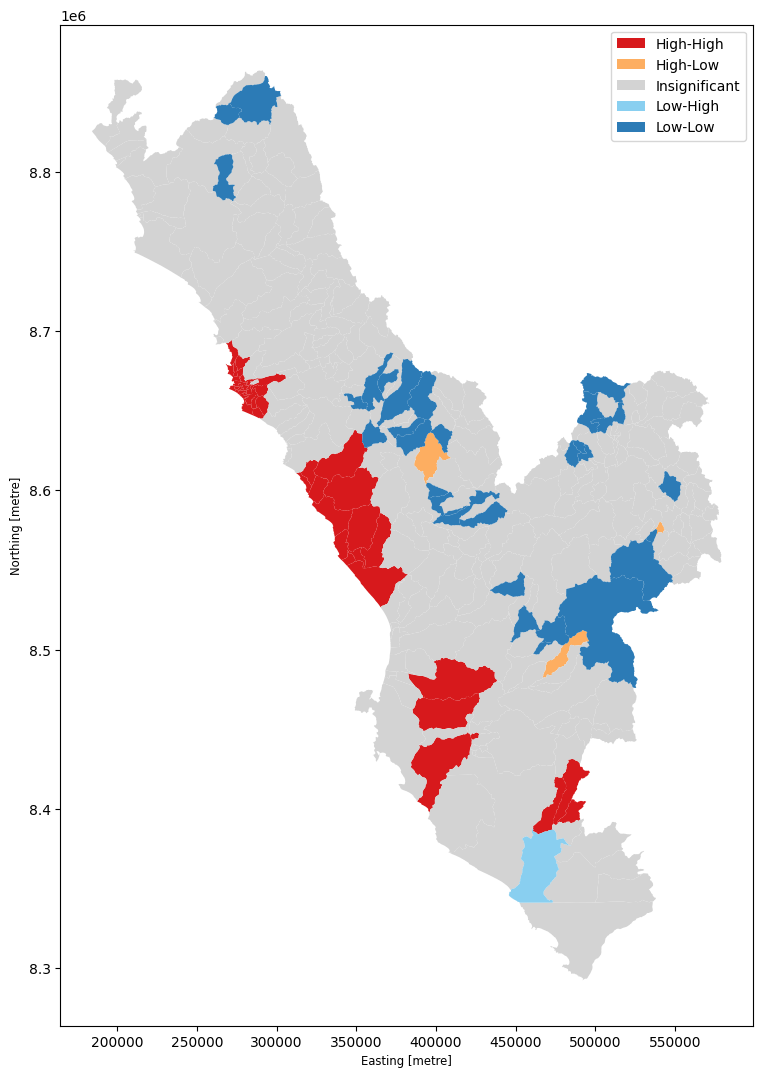

In [61]:

# Representar los resultados del análisis LISA
lisa.plot(
    peru_clean,
    crit_value=0.05,
    figsize=(10, 13),
    legend=True
)



### 6.3. Clasificación de los patrones LISA

Se identifican las categorías de asociación espacial de cada distrito, considerando un nivel de significancia del 5 %. Luego, se revisa la cantidad de distritos que pertenecen a cada categoría.


In [62]:

# Obtener las categorías del análisis LISA
peru_clean["HS_lisa"] = lisa.get_cluster_labels(crit_value=0.05)


In [63]:

# Contar los distritos de cada categoría
peru_clean["HS_lisa"].value_counts()


,count
HS_lisa,
Insignificant,233
High-High,47
Low-Low,30
High-Low,3
Low-High,1


In [64]:

# Estadísticas de la variable educativa
TheStats = ["mean", "min", "max", "var"]

# Estadísticas por categoría LISA
grouped_stats = peru_clean.groupby("HS_lisa")["Educ_sec_comp2019_pct"].agg(TheStats)

# Estadísticas del total de distritos
global_stats = peru_clean["Educ_sec_comp2019_pct"].agg(TheStats)

global_stats_df = pd.DataFrame(global_stats).T
global_stats_df.index = ["Global/Total"]

# Comparar los resultados
pd.concat([grouped_stats, global_stats_df])


,mean,min,max,var
High-High,78.468763,67.639546,89.215043,14.666061
High-Low,68.276178,62.447481,73.779273,32.181888
Insignificant,60.545318,12.358409,89.576693,188.280490
Low-High,58.375209,58.375209,58.375209,NaN
Low-Low,50.779483,30.646338,61.943082,96.860356
Global/Total,62.362036,12.358409,89.576693,205.548175



### 6.4. Personalización de las categorías LISA

Se modifican los nombres de las categorías para distinguir las agrupaciones de valores altos y bajos, los valores atípicos espaciales y los distritos sin asociación significativa. Finalmente, se asigna una paleta de colores para representar los resultados.


In [65]:

# Revisar las categorías identificadas
peru_clean["HS_lisa"].unique()


array(['Insignificant', 'Low-Low', 'High-High', 'High-Low', 'Low-High'],
      dtype=object)

In [66]:

# Categorías originales
oldLabels = [
    "Insignificant",
    "Low-Low",
    "High-High",
    "High-Low",
    "Low-High"
]

# Categorías personalizadas
newLabels = [
    "3 no_pattern",
    "4 coldSpot",
    "2 hotSpot",
    "1 hotOutlier",
    "5 coldOutlier"
]

# Crear el diccionario de equivalencias
labels = dict(zip(oldLabels, newLabels))

labels


{'Insignificant': '3 no_pattern',
 'Low-Low': '4 coldSpot',
 'High-High': '2 hotSpot',
 'High-Low': '1 hotOutlier',
 'Low-High': '5 coldOutlier'}

In [67]:

# Reemplazar los nombres de las categorías LISA
peru_clean["HS_lisa"] = peru_clean["HS_lisa"].replace(labels)

# Contar los distritos por categoría
peru_clean["HS_lisa"].value_counts().sort_index()


,count
HS_lisa,
1 hotOutlier,3
2 hotSpot,47
3 no_pattern,233
4 coldSpot,30
5 coldOutlier,1



### 6.5. Mapa LISA con vecindad ponderada por perímetro

Se representa la distribución espacial de las categorías LISA utilizando la paleta de colores `PuOr`. El mapa permite identificar agrupaciones espaciales y valores atípicos relacionados con el porcentaje de educación secundaria de los distritos seleccionados.


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

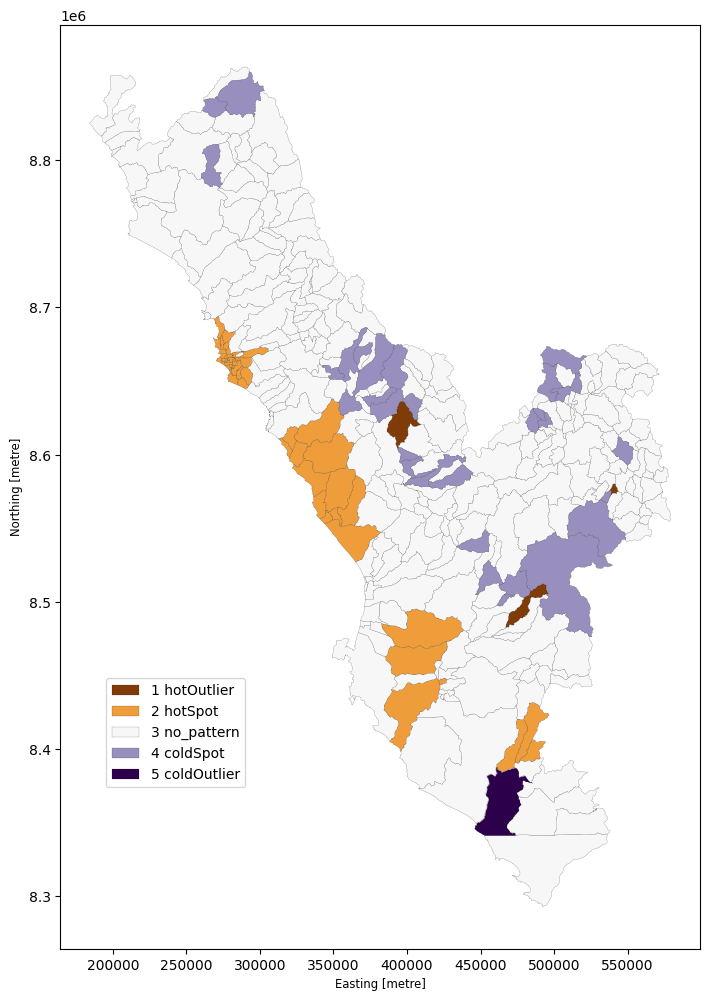

In [68]:

# Configurar la paleta de colores
import matplotlib.pyplot as plt

myColMap = plt.get_cmap("PuOr", 5)

# Representar el mapa LISA personalizado
peru_clean.plot(
    column="HS_lisa",
    categorical=True,
    cmap=myColMap,
    linewidth=0.1,
    edgecolor="k",
    legend=True,
    legend_kwds={"bbox_to_anchor": (0.3, 0.3)},
    figsize=(12, 12)
)



## 7. Comparación de mapas LISA según el método de vecindad

Se calcularán tres mapas LISA adicionales utilizando Queen, KNN y Distance Band. Se mantendrá la misma variable educativa y el conjunto de distritos utilizado en el primer mapa, para comparar cómo cambian los patrones espaciales según el método de vecindad.


In [70]:

import pandas as pd
import matplotlib.pyplot as plt
import esda
from libpysal.graph import Graph

# Mantener las categorías utilizadas por el profesor
categorias = [
    "1 hotOutlier",
    "2 hotSpot",
    "3 no_pattern",
    "4 coldSpot",
    "5 coldOutlier"
]

# Equivalencias entre las categorías originales y personalizadas
etiquetas = {
    "High-Low": "1 hotOutlier",
    "High-High": "2 hotSpot",
    "Insignificant": "3 no_pattern",
    "Low-Low": "4 coldSpot",
    "Low-High": "5 coldOutlier"
}

# Utilizar la misma paleta de colores
myColMap = plt.get_cmap("PuOr", 5)

# Función para calcular y representar los mapas LISA
def mapa_lisa(grafo, titulo):

    # Normalizar los pesos espaciales
    grafo = grafo.transform("r")

    # Calcular el índice de Moran Local
    resultado_lisa = esda.Moran_Local(
        peru_clean["Educ_sec_comp2019_pct"],
        grafo,
        seed=42
    )

    # Obtener las categorías LISA
    datos = peru_clean.copy()
    valores = resultado_lisa.get_cluster_labels(crit_value=0.05)

    datos["HS_lisa"] = pd.Categorical(
        pd.Series(valores, index=datos.index).replace(etiquetas),
        categories=categorias,
        ordered=True
    )

    # Representar el mapa con los colores del profesor
    ax = datos.plot(
        column="HS_lisa",
        categorical=True,
        cmap=myColMap,
        linewidth=0.1,
        edgecolor="k",
        legend=True,
        legend_kwds={"bbox_to_anchor": (0.3, 0.3)},
        figsize=(12, 12)
    )

    ax.set_title(titulo)
    plt.show()

    # Mostrar la cantidad de distritos por categoría
    print(datos["HS_lisa"].value_counts().sort_index())

    return datos, resultado_lisa



### 7.1. Mapa LISA mediante vecindad Queen

Se identifican los distritos vecinos que comparten un borde o vértice. A partir de estas relaciones, se calcula el índice LISA para reconocer agrupaciones y valores atípicos espaciales del porcentaje de educación secundaria.


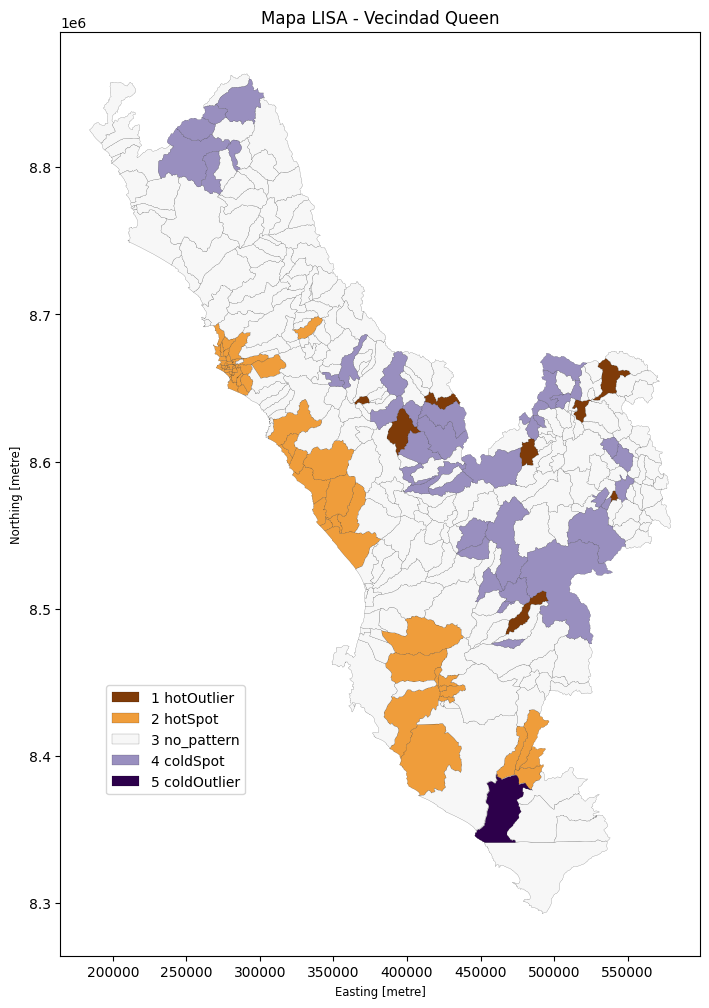

HS_lisa
1 hotOutlier       8
2 hotSpot         56
3 no_pattern     210
4 coldSpot        39
5 coldOutlier      1
Name: count, dtype: int64


In [71]:

# Construir la vecindad Queen para los distritos seleccionados
peru_queen = Graph.build_contiguity(
    peru_clean,
    rook=False
)

# Generar el mapa LISA
mapa_queen, lisa_queen = mapa_lisa(
    peru_queen,
    "Mapa LISA - Vecindad Queen"
)



### 7.2. Mapa LISA mediante vecindad KNN

Se identifican los tres distritos más cercanos a cada distrito, utilizando sus puntos representativos. Con estas relaciones se calcula el índice LISA para analizar los patrones espaciales de la variable educativa.


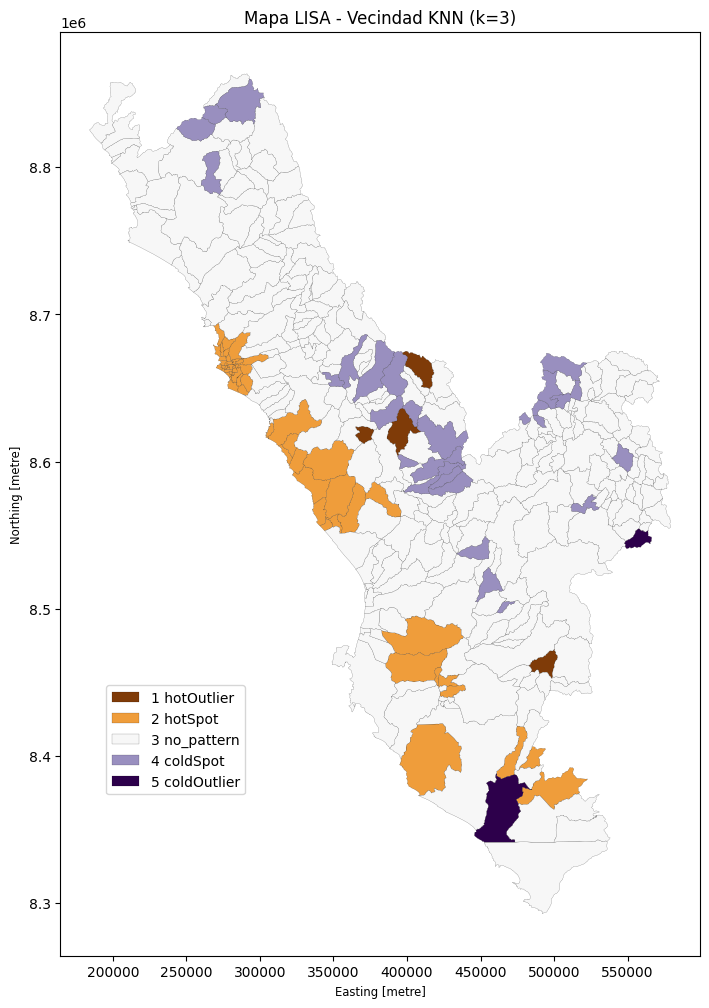

HS_lisa
1 hotOutlier       4
2 hotSpot         52
3 no_pattern     229
4 coldSpot        27
5 coldOutlier      2
Name: count, dtype: int64


In [72]:

# Construir la vecindad con tres vecinos más cercanos
peru_knn = Graph.build_knn(
    peru_clean.representative_point(),
    k=3
)

# Generar el mapa LISA
mapa_knn, lisa_knn = mapa_lisa(
    peru_knn,
    "Mapa LISA - Vecindad KNN (k=3)"
)



### 7.3. Mapa LISA mediante Distance Band

Se identifican los distritos cuyos puntos representativos se encuentran dentro de una distancia determinada. Se parte de un radio de 100 km, ampliándolo únicamente si existen distritos sin vecinos, para calcular el índice LISA.


Distancia utilizada: 100.0 km


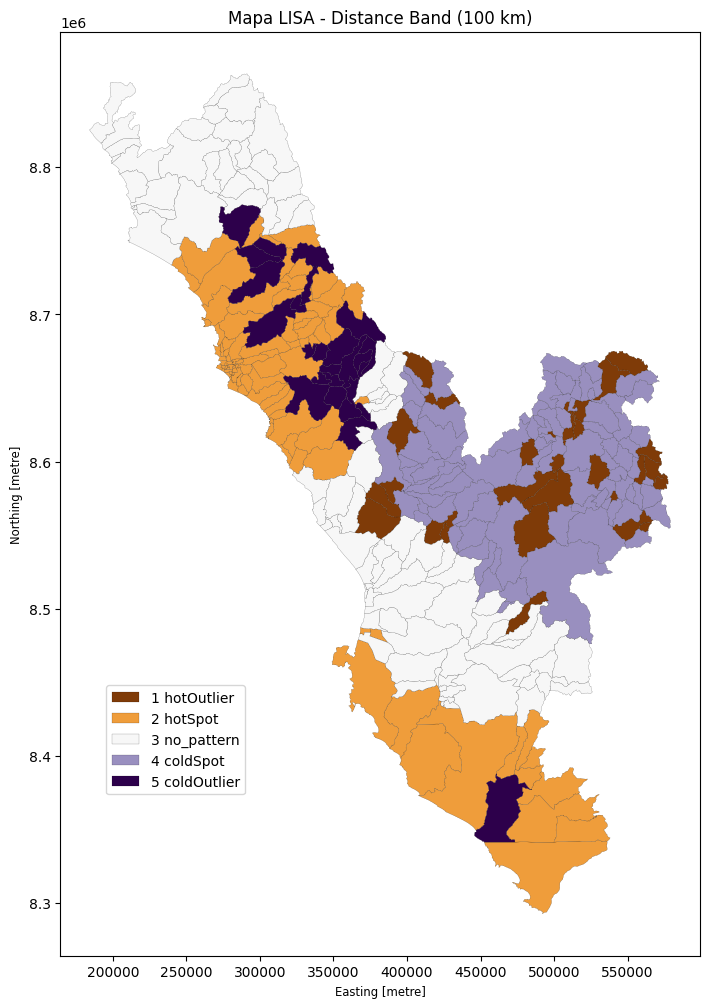

HS_lisa
1 hotOutlier     30
2 hotSpot        89
3 no_pattern     87
4 coldSpot       82
5 coldOutlier    26
Name: count, dtype: int64


In [73]:

# Obtener los puntos representativos de los distritos
puntos = peru_clean.representative_point()

# Establecer una distancia inicial de 100 km
umbral = 100000

# Construir los vecindarios por distancia
peru_band = Graph.build_distance_band(
    puntos,
    threshold=umbral
)

# Ampliar la distancia si existen distritos sin vecinos
while len(peru_band.isolates) > 0:
    umbral += 25000
    peru_band = Graph.build_distance_band(
        puntos,
        threshold=umbral
    )

print("Distancia utilizada:", umbral / 1000, "km")

# Generar el mapa LISA
mapa_band, lisa_band = mapa_lisa(
    peru_band,
    f"Mapa LISA - Distance Band ({umbral / 1000:g} km)"
)



## 8. Comparación de resultados

Se compara la cantidad de distritos clasificados en cada patrón LISA según los cuatro métodos de vecindad utilizados.


In [74]:

# Comparar las categorías obtenidas con cada método
comparacion = pd.DataFrame({
    "Perímetro": peru_clean["HS_lisa"].value_counts(),
    "Queen": mapa_queen["HS_lisa"].value_counts(),
    "KNN": mapa_knn["HS_lisa"].value_counts(),
    "Distance Band": mapa_band["HS_lisa"].value_counts()
})

# Ordenar las categorías y completar valores faltantes
comparacion = comparacion.reindex(categorias).fillna(0).astype(int)

comparacion


,Perímetro,Queen,KNN,Distance Band
HS_lisa,,,,
1 hotOutlier,3,8,4,30
2 hotSpot,47,56,52,89
3 no_pattern,233,210,229,87
4 coldSpot,30,39,27,82
5 coldOutlier,1,1,2,26
